# Marte tiene dos lunas y una asignatura pendiente

**Categoría: EDA (análisis exploratorio de datos). Fecha de corte: 21 de octubre de 2026.**

La misión japonesa MMX acaba de despegar hacia Fobos. Me pregunto **qué cambia al separar entrar en órbita y trabajar en la superficie, y qué parte de ese historial sirve para entender el reto de sus lunas**.

Reconstruyo 49 campañas de lanzamiento de 1960 a 2026. Analizo las 47 lanzadas hasta 2020, con resultados conocidos para los hitos que estudio. Dejo ESCAPADE y MMX fuera de las tasas porque todavía no han llegado a su destino. No predigo su resultado ni interpreto las frecuencias históricas como probabilidades futuras.

## Ruta de lectura y palabras necesarias

Primero documento el origen de cada fila y preparo los datos. Después comparo dos periodos por año de lanzamiento, reviso los casos que cambian según la definición y termino con las tres campañas anteriores que llevaban módulos a Fobos.

- **Campaña:** agrupo una misión y los aparatos que salieron juntos. Así cuento una sola vez Mars Polar Lander y Deep Space 2, Phobos-Grunt y Yinghuo-1, o Perseverance e Ingenuity. No cuento cada componente como intento independiente.
- **Órbita:** considero conseguida la entrada de al menos un orbitador previsto en una órbita ligada a Marte. No exijo completar todos sus objetivos científicos ni seguir activo hoy.
- **Superficie operativa:** exijo comunicaciones y trabajo desde el suelo durante más de un día terrestre. Así distingo llegar físicamente de poder trabajar. Reviso por separado Mars 3 y Beagle 2.
- **Vacío:** reservo las celdas sin dato para hitos no previstos o pendientes. Nunca los convierto en fallos.

Las campañas de órbita y superficie se solapan: algunas pretendían ambas cosas. No construyo un embudo con sus denominadores.

## 1. Origen y alcance

Parto de la [cronología de exploración de Marte de NASA/NSSDCA](https://nssdc.gsfc.nasa.gov/planetary/chronology_mars.html) y de la [tabla histórica de JPL](https://www.jpl.nasa.gov/news/press_kits/insight/landing/appendix/history/). Contrasto las novedades y los casos ambiguos con páginas de ESA, JAXA, ISRO, CNSA y Emiratos Árabes Unidos. Conservo las copias consultadas y sus huellas SHA-256 en `fuentes.json`.

Transcribo las observaciones en `misiones_manual.csv`; no es una descarga de una base ya clasificada. Cada fila representa una campaña, cada columna describe un hito. En `fuentes` enlazo los identificadores de las páginas que sustentan la fila. En `nota` explico resultados parciales y agrupaciones.

Incluyo campañas cuyo destino principal era Marte o sus lunas. Excluyo misiones canceladas antes del lanzamiento, sobrevuelos de ayuda gravitatoria con otro destino (como Rosetta o Hera), Zond 3 (prueba que no fue a Marte) y aparatos auxiliares sin un lanzamiento propio (como MarCO). No presento este recuento como el de todos los objetos que han pasado cerca de Marte.

Detecto erratas y diferencias en las fuentes: JPL llama sobrevuelo a Sputnik 24, mientras NSSDCA lo clasifica como aterrizador. Adopto NSSDCA y compruebo después cuánto cambia al excluirlo. Para Kosmos 419 adopto la descripción de orbitador de NASA SP-4524. Uso solo el año del lanzamiento, evitando diferencias de día por huso horario y erratas de fechas en la tabla JPL.

In [1]:
# importo las herramientas y fijo rutas relativas para poder repetir el análisis
from pathlib import Path
import hashlib
import json
import platform
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
if not (base / "misiones_manual.csv").exists():
    raise FileNotFoundError("Abro el notebook desde la carpeta que contiene los CSV y fuentes.json")
color_principal = "#446ddf"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

Python 3.12.10 | pandas 3.0.2 | matplotlib 3.10.8


## 2. Preparación de datos

Conservo intacta la transcripción manual. Leo las columnas de hitos como enteros que admiten vacíos. Creo la variable de periodo con el año de lanzamiento: 1960–1999 frente a 2000–2020. Este corte facilita la lectura, pero no demuestra que el cambio de siglo causase una mejora. Más adelante muevo la frontera para comprobar la sensibilidad.

In [2]:
# preparo una copia y mantengo los vacíos para no inventar resultados
datos_originales = pd.read_csv(base / "misiones_manual.csv")
datos = datos_originales.copy()
columnas_binarias = ["salida_tierra", "orbita_prevista", "orbita_lograda", "superficie_operativa"]
for columna in columnas_binarias:
    datos[columna] = pd.to_numeric(datos[columna], errors="raise").astype("Int64")
datos["periodo"] = datos["anio"].map(lambda anio: "1960–1999" if anio < 2000 else ("2000–2020" if anio <= 2020 else "Pendiente"))
historico = datos.loc[datos["anio"] <= 2020].copy()
pendientes = datos.loc[datos["anio"] > 2020].copy()
display(datos[["mision", "anio", "periodo", "orbita_prevista", "orbita_lograda", "superficie_destino", "superficie_operativa"]])

,mision,anio,periodo,orbita_prevista,orbita_lograda,superficie_destino,superficie_operativa
0,Mars 1960A,1960,1960–1999,0,<NA>,ninguna,<NA>
1,Mars 1960B,1960,1960–1999,0,<NA>,ninguna,<NA>
2,Sputnik 22,1962,1960–1999,0,<NA>,ninguna,<NA>
3,Mars 1,1962,1960–1999,0,<NA>,ninguna,<NA>
4,Sputnik 24,1962,1960–1999,0,<NA>,Marte,0
5,Mariner 3,1964,1960–1999,0,<NA>,ninguna,<NA>
6,Mariner 4,1964,1960–1999,0,<NA>,ninguna,<NA>
7,Zond 2,1964,1960–1999,0,<NA>,ninguna,<NA>
8,Mariner 6,1969,1960–1999,0,<NA>,ninguna,<NA>
9,Mariner 7,1969,1960–1999,0,<NA>,ninguna,<NA>


### Compruebo el inventario y la trazabilidad

Busco duplicados, valores inesperados y resultados asignados a hitos que no se intentaron. Compruebo también que los identificadores de fuente existen y que las copias locales conservan su contenido. El campo `salida_tierra` solo registra abandono físico del entorno terrestre; no lo empleo como sinónimo de lanzamiento sin fallos: Mariner 3 salió y aun así perdió su misión.

In [3]:
# compruebo las reglas de calidad y las copias de las fuentes
assert len(datos) == 49 and len(historico) == 47 and len(pendientes) == 2
assert not datos["mision"].duplicated().any()
assert datos["anio"].between(1960, 2026).all()
for columna in columnas_binarias:
    assert set(datos[columna].dropna().unique()) <= {0, 1}
assert datos.loc[datos["orbita_prevista"].eq(0), "orbita_lograda"].isna().all()
assert datos.loc[datos["superficie_destino"].eq("ninguna"), "superficie_operativa"].isna().all()
assert historico.loc[historico["orbita_prevista"].eq(1), "orbita_lograda"].notna().all()
assert historico.loc[historico["superficie_destino"].ne("ninguna"), "superficie_operativa"].notna().all()
assert pendientes["orbita_lograda"].isna().all()
fuentes = json.loads((base / "fuentes.json").read_text(encoding="utf-8"))
indice_fuentes = {fuente["id"]: fuente for fuente in fuentes}
for identificadores in datos["fuentes"]:
    assert set(identificadores.split("|")) <= set(indice_fuentes)
for fuente in fuentes:
    if fuente.get("archivo"):
        assert hashlib.sha256((base / fuente["archivo"]).read_bytes()).hexdigest() == fuente["sha256"]
assert all(indice_fuentes[identificador].get("archivo") for ids in datos["fuentes"] for identificador in ids.split("|"))
print("49 campañas sin duplicados; 47 con resultados históricos y 2 pendientes. Fuentes locales verificadas.")
datos.to_csv(base / "misiones_limpias.csv", index=False)

49 campañas sin duplicados; 47 con resultados históricos y 2 pendientes. Fuentes locales verificadas.


## 3. Análisis: comparo cada objetivo con sus propios intentos

Para leer una fracción como 8 de 9, pongo en el denominador solo las campañas que pretendían ese objetivo. Mantengo los fallos de lanzamiento: también forman parte de intentar llegar. Separo la superficie de Marte de la de Fobos; no mezclo sus retos físicos ni sus historiales.

In [4]:
# calculo los recuentos por periodo sin mezclar objetivos ni misiones pendientes
filas_resumen = []
for periodo, grupo in historico.groupby("periodo", sort=True):
    objetivos = {
        "Entrar en órbita de Marte": grupo.loc[grupo["orbita_prevista"].eq(1), "orbita_lograda"],
        "Trabajar en el suelo de Marte": grupo.loc[grupo["superficie_destino"].eq("Marte"), "superficie_operativa"]
    }
    for objetivo, valores in objetivos.items():
        filas_resumen.append({"periodo": periodo, "objetivo": objetivo, "conseguidos": int(valores.sum()), "intentos": len(valores), "porcentaje": round(float(valores.mean()) * 100, 2)})
resumen = pd.DataFrame(filas_resumen)
display(resumen)
resumen.to_csv(base / "resumen_periodos.csv", index=False)

,periodo,objetivo,conseguidos,intentos,porcentaje
0,1960–1999,Entrar en órbita de Marte,8,18,44.44
1,1960–1999,Trabajar en el suelo de Marte,3,10,30.00
2,2000–2020,Entrar en órbita de Marte,8,9,88.89
3,2000–2020,Trabajar en el suelo de Marte,7,9,77.78


Al comparar los resultados, encuentro **8 entradas en órbita de 18 intentos antes de 2000 y 8 de 9 desde 2000 hasta 2020**. En la superficie de Marte paso de **3 campañas operativas de 10 a 7 de 9**. Son frecuencias de campañas distintas, con agencias y diseños distintos. No atribuyo el cambio a una causa única ni calculo una probabilidad de éxito para MMX.

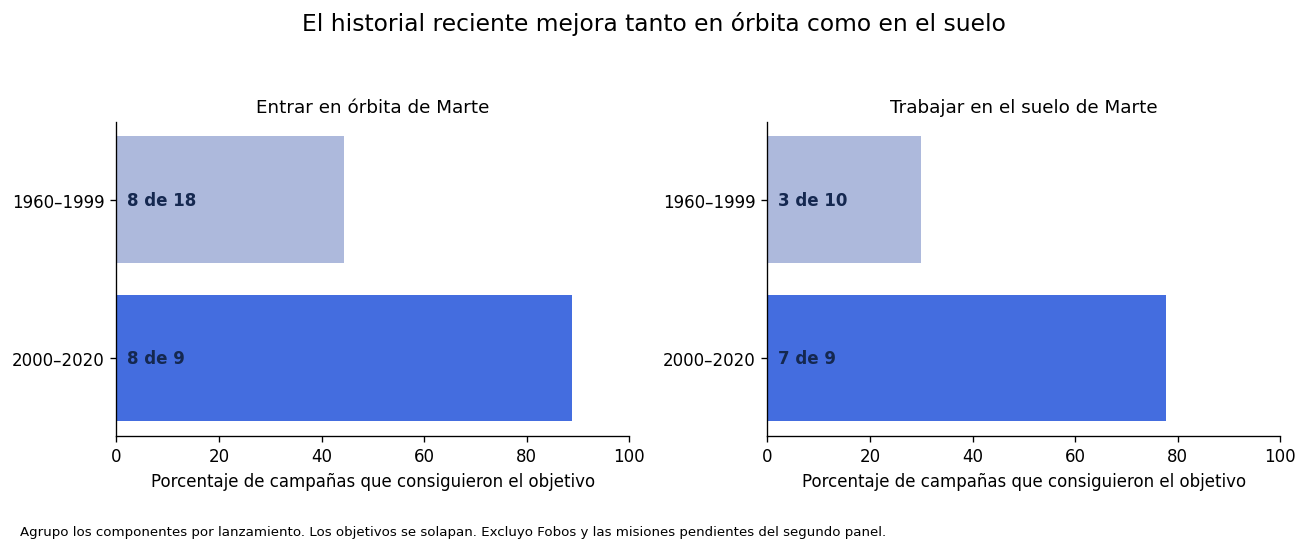

In [5]:
# dibujo los resultados con sus denominadores para hacer visible el tamaño de cada grupo
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
for eje, objetivo in zip(ejes, resumen["objetivo"].unique()):
    seleccion = resumen.loc[resumen["objetivo"].eq(objetivo)]
    barras = eje.barh(seleccion["periodo"], seleccion["porcentaje"], color=["#adb9dc", color_principal])
    for barra, fila in zip(barras, seleccion.itertuples()):
        eje.text(2, barra.get_y() + barra.get_height()/2, f"{fila.conseguidos} de {fila.intentos}", va="center", color="#152850", weight="bold")
    eje.set_xlim(0, 100)
    eje.set_xlabel("Porcentaje de campañas que consiguieron el objetivo")
    eje.set_title(objetivo, fontsize=11)
    eje.invert_yaxis()
fig.suptitle("El historial reciente mejora tanto en órbita como en el suelo", fontsize=14)
fig.text(0.02, 0.01, "Agrupo los componentes por lanzamiento. Los objetivos se solapan. Excluyo Fobos y las misiones pendientes del segundo panel.", fontsize=8)
fig.tight_layout(rect=[0, .06, 1, .93])
plt.show()

## 4. Una misión puede tener dos resultados

Para explicar qué se pierde con la etiqueta de éxito o fracaso, reviso las campañas que llevaban un orbitador y un módulo para el suelo de Marte. Busco las que lograron la órbita pero no un trabajo prolongado desde la superficie.

In [6]:
# identifico los resultados divididos que una etiqueta única escondería
resultados_divididos = historico.loc[
    historico["superficie_destino"].eq("Marte") & historico["orbita_lograda"].eq(1) & historico["superficie_operativa"].eq(0),
    ["mision", "anio", "nota", "fuentes"]
]
display(resultados_divididos)

,mision,anio,nota,fuentes
14,Mars 2,1971,Orbitador en Marte; módulo de descenso se estr...,historia|cronologia
15,Mars 3,1971,Orbitador en Marte; señal desde la superficie ...,historia|cronologia
33,Mars Express / Beagle 2,2003,Orbitador operativo; Beagle 2 llegó pero nunca...,beagle|historia
42,ExoMars 2016 / Schiaparelli,2016,TGO entró en órbita; Schiaparelli se estrelló,tgo|schiaparelli


Encuentro cuatro campañas: **Mars 2, Mars 3, Mars Express/Beagle 2 y ExoMars 2016/Schiaparelli**. No las declaro cuatro fracasos totales: en todas hubo un orbitador que sí entró en órbita. Tampoco equiparo sus problemas: Mars 3 emitió brevemente desde el suelo y Beagle 2 parece haber aterrizado, pero nunca comunicó desde allí. En los otros dos casos hubo un impacto destructivo.

## 5. Compruebo cuánto depende el resultado de mis decisiones

No equiparo contacto físico con trabajo de más de un día. Para comprobar la dependencia de esta decisión, recalculo el historial antiguo admitiendo Mars 3; después admito también la llegada física de Beagle 2 en el reciente. Finalmente excluyo Sputnik 24, cuyo objetivo aparece de forma distinta en las fuentes, y muevo el corte temporal a 1990 y 2010.

No convierto el análisis en un ranking de agencias: sus campañas no son comparables y los grupos son pequeños.

In [7]:
# pruebo definiciones alternativas sin modificar mi criterio principal
superficie_marte = historico.loc[historico["superficie_destino"].eq("Marte")].copy()
antiguas = superficie_marte.loc[superficie_marte["anio"] < 2000].copy()
recientes = superficie_marte.loc[superficie_marte["anio"] >= 2000].copy()
antiguas_contacto = antiguas.copy()
antiguas_contacto.loc[antiguas_contacto["mision"].eq("Mars 3"), "superficie_operativa"] = 1
recientes_contacto = recientes.copy()
recientes_contacto.loc[recientes_contacto["mision"].eq("Mars Express / Beagle 2"), "superficie_operativa"] = 1
variantes = [
    ("Trabajo de más de un día, 1960–1999", antiguas),
    ("Admito el breve contacto de Mars 3, 1960–1999", antiguas_contacto),
    ("Excluyo Sputnik 24, 1960–1999", antiguas.loc[antiguas["mision"].ne("Sputnik 24")]),
    ("Trabajo de más de un día, 2000–2020", recientes),
    ("Admito llegada física de Beagle 2, 2000–2020", recientes_contacto)
]
pruebas = [{"criterio": etiqueta, "logros": int(grupo["superficie_operativa"].sum()), "intentos": len(grupo)} for etiqueta, grupo in variantes]
sensibilidad = pd.DataFrame(pruebas)
sensibilidad["porcentaje"] = sensibilidad["logros"].div(sensibilidad["intentos"]).mul(100).round(2)
display(sensibilidad)
superficie_marte = historico.loc[historico["superficie_destino"].eq("Marte")]
for corte in [1990, 2000, 2010]:
    anterior = superficie_marte.loc[superficie_marte["anio"] < corte, "superficie_operativa"]
    posterior = superficie_marte.loc[superficie_marte["anio"] >= corte, "superficie_operativa"]
    print(f"Corte {corte}: antes {int(anterior.sum())}/{len(anterior)}; después {int(posterior.sum())}/{len(posterior)}")
sensibilidad.to_csv(base / "sensibilidad.csv", index=False)

,criterio,logros,intentos,porcentaje
0,"Trabajo de más de un día, 1960–1999",3,10,30.00
1,"Admito el breve contacto de Mars 3, 1960–1999",4,10,40.00
2,"Excluyo Sputnik 24, 1960–1999",3,9,33.33
3,"Trabajo de más de un día, 2000–2020",7,9,77.78
4,"Admito llegada física de Beagle 2, 2000–2020",8,9,88.89


Corte 1990: antes 2/7; después 8/12
Corte 2000: antes 3/10; después 7/9
Corte 2010: antes 6/14; después 4/5


Las decisiones cambian las cifras, pero mantengo una conclusión prudente: el historial de trabajo desde el suelo de Marte es mejor en las campañas recientes bajo las alternativas examinadas. No afirmo que la tecnología sea la única explicación ni que las etapas sean ensayos independientes. En el periodo reciente las siete campañas operativas no cambian al admitir el contacto fugaz de Mars 3, que pertenece al antiguo.

## 6. Fobos: tres antecedentes, tres interrupciones distintas

Recupero las campañas anteriores con módulos destinados a la superficie de Fobos. Dejo fuera los sobrevuelos de observación que nunca pretendieron posarse. MMX es la cuarta campaña de este inventario con ese objetivo, pero su resultado aún no existe.

In [8]:
# separo los antecedentes de fobos y hago visible qué puerta logró cruzar cada uno
fobos = historico.loc[historico["superficie_destino"].eq("Fobos")].copy()
display(fobos[["mision", "anio", "salida_tierra", "orbita_lograda", "superficie_operativa", "nota"]])
assert len(fobos) == 3 and int(fobos["superficie_operativa"].sum()) == 0
print(f"{len(fobos)} campañas anteriores; {int(fobos['salida_tierra'].sum())} salieron de la Tierra; {int(fobos['orbita_lograda'].sum())} orbitó Marte; ninguna trabajó en el suelo de Fobos.")

,mision,anio,salida_tierra,orbita_lograda,superficie_operativa,nota
23,Phobos 1,1988,1,0,0,Pérdida de orientación durante el viaje
24,Phobos 2,1988,1,1,0,Orbitó Marte y observó Fobos; perdió el contac...
38,Phobos-Grunt / Yinghuo-1,2011,0,0,0,Agrupados la sonda rusa y el orbitador chino; ...


3 campañas anteriores; 2 salieron de la Tierra; 1 orbitó Marte; ninguna trabajó en el suelo de Fobos.


Phobos 1 perdió el contacto durante el viaje. Phobos 2 sí orbitó Marte y observó Fobos, pero se perdió antes de liberar los módulos de superficie. Phobos-Grunt ni siquiera abandonó la órbita terrestre. **No son tres aterrizajes fallidos sobre Fobos:** ninguna llegó a ejecutar esa fase. No uso este grupo de tres para calcular el riesgo de MMX.

Con el calendario de JAXA distingo los hechos observados de los planes: MMX despegó el 20 de octubre de 2026 a las 04:41:03 de Japón (19 de octubre a las 21:41:03 en la España peninsular). La llegada al entorno marciano en 2027, la toma de material y el regreso en 2031 siguen siendo objetivos. ESCAPADE también permanece pendiente, con llegada prevista en 2027.

## 7. Exporto resultados y dejo comprobaciones para el artículo

Guardo los recuentos y las filas de la tabla interactiva. Así puedo generar los gráficos de la web desde los mismos números que acabo de calcular. Los gráficos de la web se dibujan mediante código, no con capturas de este notebook.

In [9]:
# exporto resultados reproducibles y compruebo las cifras que voy a contar
resumen_publicable = {
    "categoria": "EDA", "fecha_corte": "2026-10-21", "campanas": len(datos), "historicas": len(historico),
    "pendientes": pendientes["mision"].tolist(), "periodos": resumen.to_dict(orient="records"),
    "fobos_antecedentes": len(fobos), "fobos_superficie_operativa": int(fobos["superficie_operativa"].sum()),
    "resultados_divididos": resultados_divididos["mision"].tolist()
}
assert resumen["conseguidos"].tolist() == [8, 3, 8, 7]
assert resumen["intentos"].tolist() == [18, 10, 9, 9]
(base / "resultados.json").write_text(json.dumps(resumen_publicable, ensure_ascii=False, indent=2), encoding="utf-8")
tabla_web = json.loads(datos.to_json(orient="records", force_ascii=False))
(base / "misiones_web.json").write_text(json.dumps(tabla_web, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame([{ "campañas en el inventario": len(datos), "con resultado histórico": len(historico), "pendientes": len(pendientes), "resultados divididos": len(resultados_divididos)}]))

,campañas en el inventario,con resultado histórico,pendientes,resultados divididos
0,49,47,2,4


## Conclusión y límites

Encuentro una mejora histórica en los dos objetivos que puedo comparar: entrar en órbita de Marte y trabajar desde su suelo. También encuentro cuatro campañas cuyo resultado cambia según mire el orbitador o el módulo de superficie. Por eso evito resumir décadas de exploración en un único porcentaje de éxito.

Para entender MMX, el historial de Fobos aporta otra lectura: las tres campañas anteriores quedaron interrumpidas antes de operar en su superficie, y dos de ellas antes de orbitar Marte. La barrera sigue pendiente, pero el inventario no permite cuantificar sus causas ni pronosticar el nuevo intento.

Trabajo con una clasificación editorial manual, revisable y trazable, no con una clasificación oficial. No mido toda la producción científica, las diferencias de presupuesto, todos los subsistemas ni los retrasos. Agrupo componentes que comparten lanzamiento y no trato las observaciones como ensayos independientes. Algunas fuentes históricas contienen erratas y abreviaciones; dejo documentados los conflictos que afectan a mi clasificación. La actualización de resultados de navegación se detiene en la fecha de corte. Para repetir los cálculos no necesito conexión: los CSV y las copias consultadas viajan junto al notebook.

## Fuentes consultadas

Cada identificador utilizado en el CSV se resuelve en esta lista. Conservo el manifiesto completo en `fuentes.json`.

In [10]:
# muestro las direcciones para que pueda auditarse cada decisión
display(pd.DataFrame(fuentes)[["id", "url", "consulta", "archivo"]])

,id,url,consulta,archivo
0,beagle,https://www.esa.int/Science_Exploration/Space_...,2026-10-21,fuentes/beagle.html
1,cronica,https://www.nasa.gov/wp-content/uploads/2023/0...,2026-10-21,fuentes/cronica.pdf
2,cronologia,https://nssdc.gsfc.nasa.gov/planetary/chronolo...,2026-10-21,fuentes/cronologia.html
3,curiosity,https://science.nasa.gov/mission/msl-curiosity/,2026-10-21,fuentes/curiosity.html
4,dlr_mmx,https://www.dlr.de/en/latest/news/2026/mmx-mis...,2026-10-21,fuentes/dlr_mmx.html
5,escapade,https://ciencia.nasa.gov/sistema-solar/mision-...,2026-10-21,fuentes/escapade.html
6,grunt,https://www.esa.int/Enabling_Support/Operation...,2026-10-21,fuentes/grunt.html
7,grunt_fin,https://www.esa.int/Space_Safety/Space_Debris/...,2026-10-21,fuentes/grunt_fin.html
8,historia,https://www.jpl.nasa.gov/news/press_kits/insig...,2026-10-21,fuentes/historia_web.txt
9,hope,https://www.mofa.gov.ae/en/missions/warsaw/med...,2026-10-21,fuentes/hope.html
